# WAF par machine learning : détection de requêtes HTTP malveillantes

ENSIBS 3A, IA pour la cybersécurité.

Ce notebook classe des requêtes HTTP comme **légitimes** (label = 0) ou **malveillantes** (label = 1) à partir du dataset SR-BH 2020 (labels multi-label CAPEC). Le modèle final est exporté en models/waf.joblib puis utilisé par l'API de déploiement.

## Plan

1. **Données et prétraitement** : exploration, nettoyage, dédoublonnage, split train / test.
2. **Modèle TF-IDF** : comparaison des classifieurs, réglage, seuil, évaluation finale sur le test, export.
3. **Modèle à marqueurs** : marqueurs experts, sélection, mix TF-IDF + marqueurs, expérience avec / sans Referer.
4. **Tests du modèle** : requêtes d'attaque et mesure des faux positifs.
5. **Synthèse**.

## Exécution

Le notebook se lance depuis le dossier notebooks/ (les chemins sont relatifs : ../data, ../models, ../rapport) et utilise preprocessing.py situé à la racine du dépôt. Le fichier data/data_capec_multilabel.csv doit être présent. Pour reproduire les résultats : *Restart & Run All*.

Dépendances : pandas, numpy, matplotlib, scikit-learn, xgboost, pyarrow, joblib.

```bash
pip install pandas numpy matplotlib scikit-learn xgboost pyarrow joblib
```

## Imports communs

In [ ]:
import sys, os, time
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (make_scorer, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, roc_curve,
                             f1_score, precision_score, recall_score)
from xgboost import XGBClassifier

from preprocessing import build_text_df, REQ_COLS, marqueurs, MARQUEURS_RETENUS

os.makedirs("../models", exist_ok=True)
os.makedirs("../rapport", exist_ok=True)

pd.set_option("display.max_colwidth", 120)

# Partie 1 : Données et prétraitement

Objectif : transformer le CSV brut en train.parquet et test.parquet utilisables par les modèles.

## 1. Chargement
On lit tout en texte (`dtype=str`) pour éviter les types mélangés et les faux doublons (`"1"` contre `1`).

In [ ]:
df = pd.read_csv("../data/data_capec_multilabel.csv", dtype=str)
print(df.shape)
print(df.columns.tolist())

(907815, 38)
['timestamp', 'src_ip', 'src_port', 'dst_ip', 'dst_port', 'request_http_method', 'request_http_request', 'request_http_protocol', 'request_user_agent', 'request_referer', 'request_host', 'request_origin', 'request_cookie', 'request_content_type', 'request_accept', 'request_accept_language', 'request_accept_encoding', 'request_do_not_track', 'request_connection', 'request_body', 'response_http_protocol', 'response_http_status_code', 'response_http_status_message', 'response_content_length', '000 - Normal', '272 - Protocol Manipulation', '242 - Code Injection', '88 - OS Command Injection', '126 - Path Traversal', '66 - SQL Injection', '16 - Dictionary-based Password Attack', '310 - Scanning for Vulnerable Software', '153 - Input Data Manipulation', '248 - Command Injection', '274 - HTTP Verb Tampering', '194 - Fake the Source of Data', '34 - HTTP Response Splitting', '33 - HTTP Request Smuggling']


## 2. Exploration
Constats principaux : 907 815 requêtes, 58 % légitimes / 42 % malveillantes, SQL Injection dominant, `248 - Command Injection` quasi absent (1 requête), 9 238 requêtes multi-label, colonnes vides à 100 % (`request_do_not_track`, `request_origin`), et une fuite par le code de réponse (règle « 200 = légitime » donnant ~82 % d'accuracy).

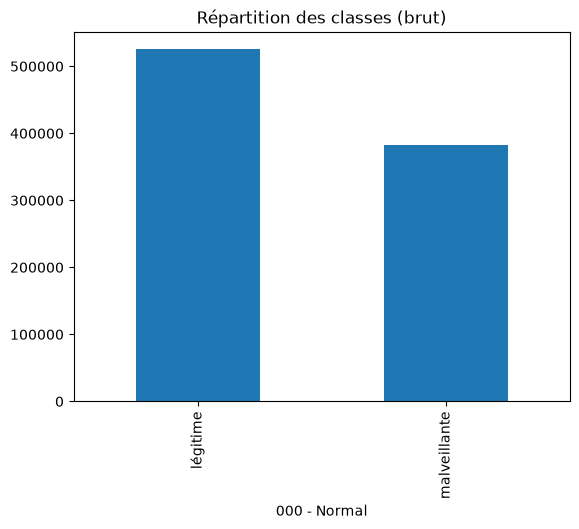

In [ ]:
# Graphique 1 : équilibre des classes
df["000 - Normal"].map({"1": "légitime", "0": "malveillante"}).value_counts().plot.bar(title="Répartition des classes (brut)")
plt.savefig("../rapport/fig_classes.png", bbox_inches="tight")
plt.show()

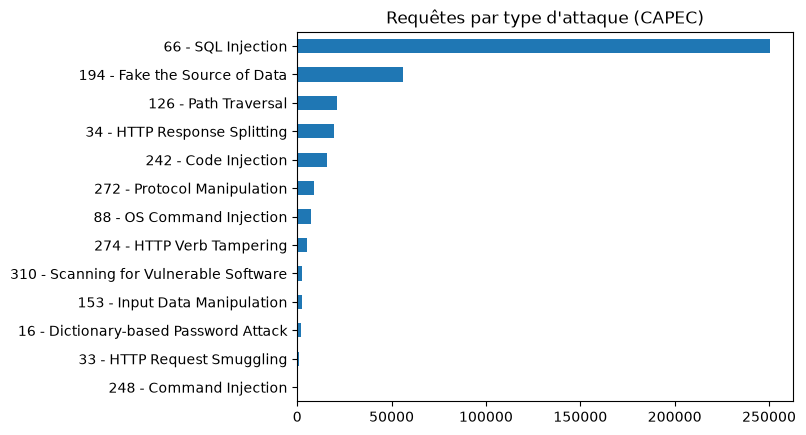

In [ ]:
# Graphique 2 : types d'attaque
label_cols = df.columns[24:].tolist()
attack_cols = label_cols[1:]
df[attack_cols].astype(int).sum().sort_values().plot.barh(title="Requêtes par type d'attaque (CAPEC)")
plt.savefig("../rapport/fig_attaques.png", bbox_inches="tight")
plt.show()

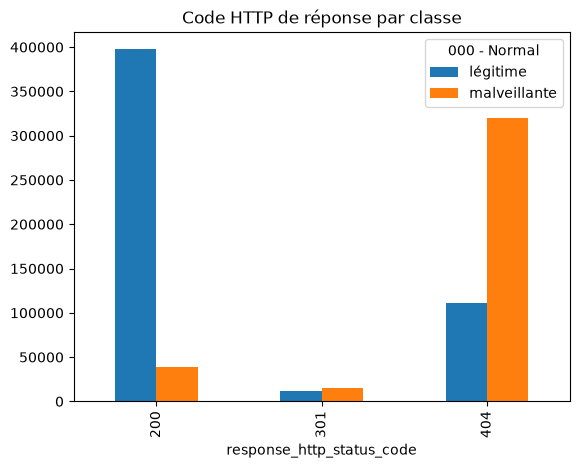

In [ ]:
# Graphique 3 : la fuite par le code de réponse
ct = pd.crosstab(df["response_http_status_code"], df["000 - Normal"].map({"1": "légitime", "0": "malveillante"}))
ct.loc[["200", "301", "404"]].plot.bar(title="Code HTTP de réponse par classe")
plt.savefig("../rapport/fig_codes_http.png", bbox_inches="tight")
plt.show()

## 3. Labels
`label = 1 - "000 - Normal"` : 1 = malveillante (ce qu'on cherche à détecter), 0 = légitime. On garde les 13 colonnes CAPEC pour le bonus de type d'attaque.

In [ ]:
label_cols  = df.columns[24:].tolist()   # 000 - Normal + 13 CAPEC
attack_cols = label_cols[1:]               # les 13 CAPEC

df[label_cols] = df[label_cols].astype(int)
df["label"] = 1 - df["000 - Normal"]

## 4. Suppression des colonnes
- Identifiants (timestamp, IP, ports) : le modèle apprendrait des adresses ou des heures, pas des attaques.
- `response_*` : un WAF décide avant la réponse du serveur, cette information n'existe pas en production.
- Colonnes vides à 100 % : aucune information.

In [ ]:
drop_cols = (
    ["timestamp", "src_ip", "src_port", "dst_ip", "dst_port"]
    + [c for c in df.columns if c.startswith("response_")]
    + ["request_do_not_track", "request_origin"]
    + ["000 - Normal"]
)
df = df.drop(columns=drop_cols)
df.columns.tolist()

['request_http_method',
 'request_http_request',
 'request_http_protocol',
 'request_user_agent',
 'request_referer',
 'request_host',
 'request_cookie',
 'request_content_type',
 'request_accept',
 'request_accept_language',
 'request_accept_encoding',
 'request_connection',
 'request_body',
 '272 - Protocol Manipulation',
 '242 - Code Injection',
 '88 - OS Command Injection',
 '126 - Path Traversal',
 '66 - SQL Injection',
 '16 - Dictionary-based Password Attack',
 '310 - Scanning for Vulnerable Software',
 '153 - Input Data Manipulation',
 '248 - Command Injection',
 '274 - HTTP Verb Tampering',
 '194 - Fake the Source of Data',
 '34 - HTTP Response Splitting',
 '33 - HTTP Request Smuggling',
 'label']

## 5. Construction du texte
`build_text_df` normalise Host et Referer (sinon le modèle apprend `test-site.com` et bloquerait tout en démo sur `localhost`), décode l'URL deux fois, met en minuscules et concatène les champs `request_*`.

In [ ]:
df["text"] = build_text_df(df)
for lab in (0, 1):
    print(f"--- label {lab} ---")
    for t in df[df["label"] == lab]["text"].sample(3, random_state=42):
        print(t[:200])
        print()

--- label 0 ---
request_http_method get request_http_request /blog/index.php/my-account/edit-profile/{{ data.sizes.large.url }} request_http_protocol http/1.1 request_user_agent mozilla/5.0 (x11; linux x86_64; rv:70.

request_http_method get request_http_request /blog/wp-login.php request_http_protocol http/1.1 request_user_agent mozilla/5.0 (windows nt 10.0; wow64; trident/7.0; rv:11.0) like gecko request_referer 

request_http_method get request_http_request / request_http_protocol http/1.1 request_user_agent mozilla/5.0 (windows nt 10.0; wow64; rv:37.0) gecko/20100101 firefox/37.0 request_referer  request_host

--- label 1 ---
request_http_method get request_http_request /blog'+and+'1'='1/wp-includes/js/media-audiovideo.min.js?ver=4.9.5 request_http_protocol http/1.1 request_user_agent mozilla/5.0 (x11; linux x86_64; rv:70.

request_http_method get request_http_request /blog/wp-content/uploads/2020/04/27f17687-adda-3ce6-9767-0037ea74eec2.png||sleep+15 request_http_protocol http/1.1 

## 6. Dédoublonnage et conflits
On dédoublonne après `build_text` (le décodage peut rendre identiques des requêtes différentes). Les textes contradictoires (labels 0 et 1) sont retirés dans leurs deux versions, car on ne sait pas laquelle est juste. Sans cela, la même requête se retrouverait en train et en test et les scores seraient gonflés.

In [ ]:
n_avant = len(df)

conflits = df.groupby("text")["label"].nunique()
textes_conflit = conflits[conflits > 1].index
print(len(textes_conflit), "textes contradictoires")
df = df[~df["text"].isin(textes_conflit)]

df = df.drop_duplicates(subset=["text", "label"])

print(f"{n_avant} -> {len(df)} requêtes")
df["label"].value_counts(normalize=True).round(3)

284 textes contradictoires
907815 -> 534444 requêtes


label
1    0.681
0    0.319
Name: proportion, dtype: float64

In [ ]:
print(df.shape)
print(df["label"].value_counts())
print(df["text"].str.len().describe())
assert df["text"].isna().sum() == 0
assert "label" in df.columns and "text" in df.columns

(534444, 28)
label
1    364070
0    170374
Name: count, dtype: int64
count    534444.000000
mean        692.009683
std         178.022901
min         254.000000
25%         537.000000
50%         696.000000
75%         831.000000
max        1344.000000
Name: text, dtype: float64


## 7. Split et sauvegarde
Le split est fait une seule fois, ici, pour que tout le monde évalue sur le même test. `stratify` conserve la même proportion de classes dans train et test. Le test n'est plus utilisé avant l'évaluation finale.

In [ ]:
keep = ["text", "label"] + attack_cols

train, test = train_test_split(
    df[keep], test_size=0.2, stratify=df["label"], random_state=42
)
print(len(train), len(test))
print(train["label"].mean().round(3), test["label"].mean().round(3))

train.to_parquet("../data/train.parquet", index=False)
test.to_parquet("../data/test.parquet", index=False)

sample = train.sample(50_000, random_state=42)
sample.to_parquet("../data/sample.parquet", index=False)

427555 106889
0.681 0.681


## 8. Conclusion
- Dataset d'origine : 907 815 requêtes, 38 colonnes.
- Transformations : labels binaires, suppression des identifiants, des colonnes `response_*` et des colonnes vides, normalisation Host/Referer, décodage URL, dédoublonnage.
- Pièges identifiés : fuite par le code de réponse, doublons, biais Host/Referer.
- Limites : un seul site (WordPress), données de 2020, labels en partie issus de ModSecurity, Referer probablement biaisé.

In [ ]:
# Libère la mémoire : le DataFrame brut n'est plus utilisé (les parties suivantes lisent les fichiers parquet)
del df

# Partie 2 : Modèle TF-IDF + LinearSVC

Classification binaire des requêtes HTTP (1 = malveillante) avec des n-grammes de caractères (TF-IDF) et un LinearSVC.

## Choix du modèle

Critères, dans l'ordre : F1, taux de faux positifs (FPR), temps, simplicité.

| Modèle | F1 (CV) | FPR | Durée CV 5 plis |
|---|---|---|---|
| **LinearSVC** | 0,9837 | 1,24 % | 161 s |
| XGBoost | 0,9902 | 0,89 % | 662 s |
| RandomForest | 0,9683 | 7,25 % | 233 s |
| LogReg | 0,9667 | 2,85 % | 207 s |
| NaiveBayes | 0,8806 | 30,6 % | 151 s |

- LinearSVC atteint presque la qualité de XGBoost (F1 0,9837 contre 0,9902) pour environ 4 fois moins de temps (161 s contre 662 s). Sans réglage, il égale déjà la LogReg réglée (0,9833).
- XGBoost est un peu meilleur, mais son coût d'entraînement est trop élevé pour un jeu de 427 000 lignes avec réglage et recalcul du seuil.
- RandomForest et NaiveBayes ont un FPR trop haut pour un WAF.
- LinearSVC n'a pas de `predict_proba` : on l'enveloppe dans `CalibratedClassifierCV` pour obtenir des probabilités (nécessaires pour le seuil et pour l'API).

## 0. Données (échantillon)

In [ ]:
train = pd.read_parquet("../data/sample.parquet")
X_train, y_train = train["text"], train["label"].astype(int)
print(len(X_train), round(float(y_train.mean()), 3))

## 1. Résultats de la comparaison

Validation croisée à 5 plis sur l'échantillon de 50 000 lignes. La durée comprend le TF-IDF refait à chaque pli. Baseline (« toujours malveillant ») : F1 0,811 mais FPR 1,0.

le F1 seul ne suffit pas (la baseline a déjà 0,811) ; le FPR mesure les vrais clients bloqués ; les n-grammes de caractères battent nettement les mots.

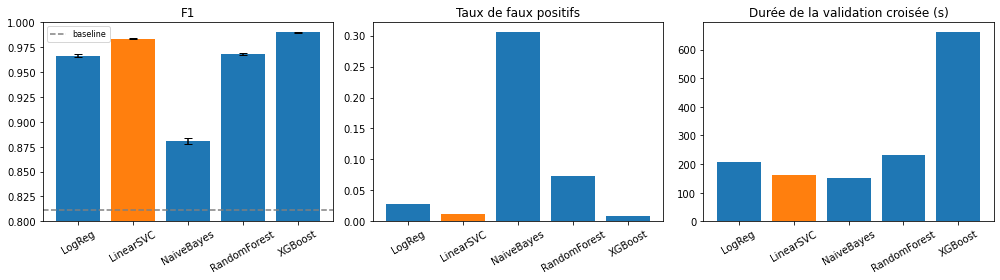

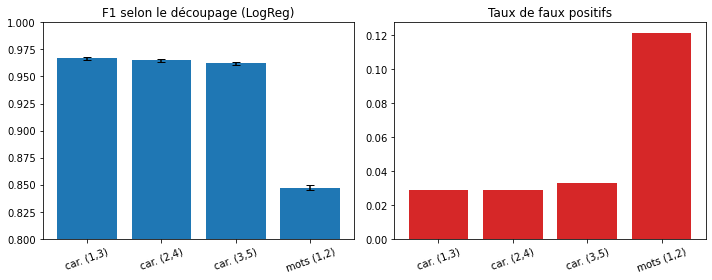

In [ ]:
# Valeurs mesurées lors de la comparaison des classifieurs (pas de recalcul ici)
resultats = pd.DataFrame({
    "f1":    [0.9667, 0.9837, 0.8806, 0.9683, 0.9902],
    "f1_std":[0.0012, 0.0004, 0.0031, 0.0009, 0.0005],
    "fpr":   [0.0285, 0.0124, 0.3061, 0.0725, 0.0089],
    "duree": [207, 161, 151, 233, 662],
}, index=["LogReg", "LinearSVC", "NaiveBayes", "RandomForest", "XGBoost"])

ng = pd.DataFrame({
    "f1":    [0.9667, 0.9648, 0.9622, 0.8473],
    "f1_std":[0.0012, 0.0013, 0.0014, 0.0024],
    "fpr":   [0.0285, 0.0289, 0.0327, 0.1212],
}, index=["car. (1,3)", "car. (2,4)", "car. (3,5)", "mots (1,2)"])

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
couleurs = ["tab:orange" if m == "LinearSVC" else "tab:blue" for m in resultats.index]
ax[0].bar(resultats.index, resultats["f1"], yerr=resultats["f1_std"], capsize=4, color=couleurs)
ax[0].axhline(0.811, color="gray", ls="--", label="baseline")
ax[0].set_ylim(0.8, 1.0); ax[0].set_title("F1"); ax[0].legend(fontsize=8)
ax[1].bar(resultats.index, resultats["fpr"], color=couleurs)
ax[1].set_title("Taux de faux positifs")
ax[2].bar(resultats.index, resultats["duree"], color=couleurs)
ax[2].set_title("Durée de la validation croisée (s)")
for a in ax:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../rapport/fig_comparaison_modeles.png", bbox_inches="tight", dpi=150)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(ng.index, ng["f1"], yerr=ng["f1_std"], capsize=4, color="tab:blue")
ax[0].set_ylim(0.8, 1.0); ax[0].set_title("F1 selon le découpage (LogReg)")
ax[1].bar(ng.index, ng["fpr"], color="tab:red")
ax[1].set_title("Taux de faux positifs")
for a in ax:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("../rapport/fig_ngrammes.png", bbox_inches="tight", dpi=150)
plt.show()

## 2. Configuration commune

- StratifiedKFold garde la proportion 68/32 dans chaque pli ; mêmes plis pour tous les essais.
- Le FPR est la métrique clé d'un WAF : un faux positif = un vrai client bloqué.
- Le Pipeline refait le TF-IDF dans chaque pli (pas de fuite) et donne un seul fichier à déployer.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def fpr(y_true, y_pred):
    """Taux de faux positifs : part des requêtes légitimes bloquées à tort."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp / (fp + tn)

def make_pipe(clf, ngram_range=(1, 3), max_features=100_000):
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=ngram_range,
                                  max_features=max_features, sublinear_tf=True)),
        ("clf", clf),
    ])

## 3. Réglage du LinearSVC (GridSearchCV, sur l'échantillon)

On règle la taille des n-grammes et `C` (force de régularisation : plus grand = moins de régularisation). Grille volontairement petite (6 combinaisons × 5 plis), avec `n_jobs=2` pour limiter la mémoire.

GridSearchCV teste toutes les combinaisons d'hyperparamètre en validation croisée et garde la meilleure.

In [ ]:
pipe = make_pipe(LinearSVC(class_weight="balanced"))
grid = {
    "tfidf__ngram_range": [(1, 3), (2, 4)],
    "clf__C": [0.1, 1, 10],
}
gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=2, verbose=1)
gs.fit(X_train, y_train)
print(gs.best_params_, round(gs.best_score_, 4))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
{'clf__C': 10, 'tfidf__ngram_range': (2, 4)} 0.9907


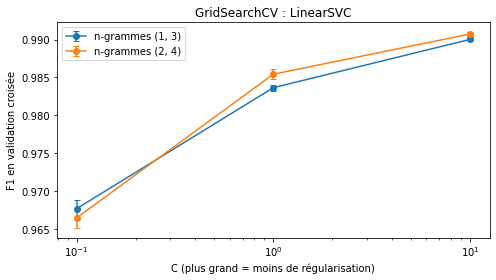

In [ ]:
res = pd.DataFrame(gs.cv_results_)
res["ngram"] = res["param_tfidf__ngram_range"].astype(str)
res["C"] = res["param_clf__C"].astype(float)

fig, ax = plt.subplots(figsize=(7, 4))
for ngr, g in res.groupby("ngram"):
    g = g.sort_values("C")
    ax.errorbar(g["C"], g["mean_test_score"], yerr=g["std_test_score"],
                marker="o", capsize=3, label=f"n-grammes {ngr}")
ax.set_xscale("log")
ax.set_xlabel("C (plus grand = moins de régularisation)")
ax.set_ylabel("F1 en validation croisée")
ax.set_title("GridSearchCV : LinearSVC")
ax.legend()
plt.tight_layout()
plt.savefig("../rapport/fig_gridsearch.png", bbox_inches="tight", dpi=150)
plt.show()

## 4. Modèle final et choix du seuil

**Calibration** : le modèle final est TF-IDF puis CalibratedClassifierCV(LinearSVC), ce qui donne un predict_proba utilisable par l'API.

**Seuil** : par défaut on bloque si proba ≥ 0,5. Pour un WAF on préfère limiter les faux positifs : on choisit le seuil qui garde au plus 1 % de légitimes bloquées. Pour aller vite sur le train complet, il est calculé sur un seul découpage du train (80 % pour entraîner, 20 % pour choisir le seuil), sans toucher au test.

Cette cellule charge le train complet et entraîne un modèle.

In [ ]:
train_full = pd.read_parquet("../data/train.parquet")
test = pd.read_parquet("../data/test.parquet")
X_train, y_train = train_full["text"], train_full["label"].astype(int)
X_test, y_test = test["text"], test["label"].astype(int)
print(len(X_train), len(X_test))

bp = gs.best_params_
def make_final():
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=bp["tfidf__ngram_range"],
                                  max_features=100_000, sublinear_tf=True)),
        ("clf", CalibratedClassifierCV(LinearSVC(C=bp["clf__C"], class_weight="balanced"), cv=3)),
    ])

# Seuil : 80 % du train pour entraîner, 20 % pour choisir
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                              stratify=y_train, random_state=42)
modele_seuil = make_final().fit(X_fit, y_fit)
proba_val = modele_seuil.predict_proba(X_val)[:, 1]

fprs, tprs, seuils = roc_curve(y_val, proba_val)
cible = 0.01                                   # au plus 1 % de légitimes bloquées
j = np.where(fprs <= cible)[0][-1]
SEUIL = float(seuils[j])
print(f"Seuil = {SEUIL:.3f} -> FPR = {fprs[j]:.4f}, détection = {tprs[j]:.4f}")

427555 106889
Seuil = 0.246 -> FPR = 0.0100, détection = 0.9947


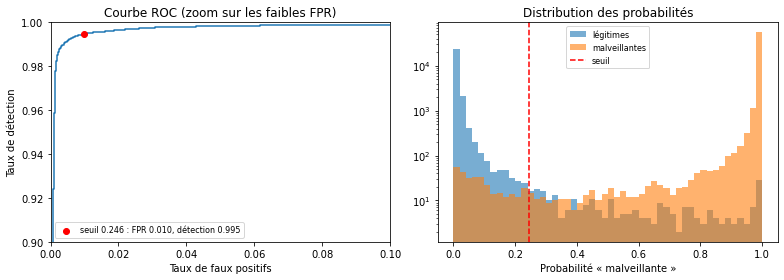

In [ ]:
yv = np.asarray(y_val)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fprs, tprs)
ax[0].scatter([fprs[j]], [tprs[j]], color="red", zorder=3,
              label=f"seuil {SEUIL:.3f} : FPR {fprs[j]:.3f}, détection {tprs[j]:.3f}")
ax[0].set_xlim(0, 0.1); ax[0].set_ylim(0.9, 1.0)
ax[0].set_xlabel("Taux de faux positifs"); ax[0].set_ylabel("Taux de détection")
ax[0].set_title("Courbe ROC (zoom sur les faibles FPR)"); ax[0].legend(fontsize=8)
ax[1].hist(proba_val[yv == 0], bins=50, alpha=0.6, label="légitimes")
ax[1].hist(proba_val[yv == 1], bins=50, alpha=0.6, label="malveillantes")
ax[1].axvline(SEUIL, color="red", ls="--", label="seuil")
ax[1].set_yscale("log")
ax[1].set_xlabel("Probabilité « malveillante »"); ax[1].set_title("Distribution des probabilités")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../rapport/fig_seuil.png", bbox_inches="tight", dpi=150)
plt.show()

## 5. Évaluation finale sur le test

On entraîne le modèle final sur tout le train, puis on évalue sur le test. On regarde aussi le rappel par type d'attaque pour vérifier que le modèle ne détecte pas que les injections SQL.

              precision    recall  f1-score   support

    légitime     0.9891    0.9892    0.9892     34075
malveillante     0.9950    0.9949    0.9949     72814

    accuracy                         0.9931    106889
   macro avg     0.9920    0.9921    0.9921    106889
weighted avg     0.9931    0.9931    0.9931    106889

FPR test : 0.0108


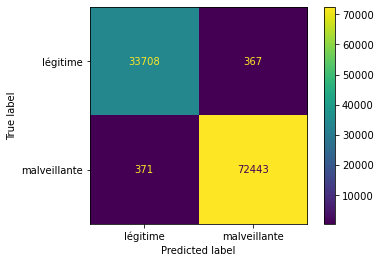

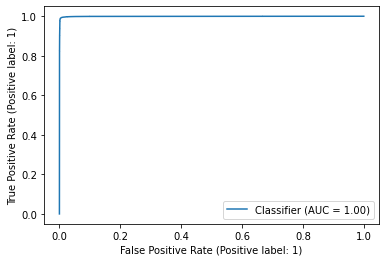

F1           0.9949
précision    0.9950
rappel       0.9949
FPR          0.0108
dtype: float64

In [ ]:
final = make_final().fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
y_pred = (proba >= SEUIL).astype(int)

print(classification_report(y_test, y_pred, target_names=["légitime", "malveillante"], digits=4))
print("FPR test :", round(fpr(y_test, y_pred), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["légitime", "malveillante"])
plt.savefig("../rapport/fig_confusion.png", bbox_inches="tight"); plt.show()

RocCurveDisplay.from_predictions(y_test, proba)
plt.savefig("../rapport/fig_roc.png", bbox_inches="tight"); plt.show()

pd.Series({
    "F1": f1_score(y_test, y_pred),
    "précision": precision_score(y_test, y_pred),
    "rappel": recall_score(y_test, y_pred),
    "FPR": fpr(y_test, y_pred),
}).round(4)

In [ ]:
# Rappel par type d'attaque
attack_cols = [c for c in test.columns if c[0].isdigit() and not c.startswith("000")]
for c in attack_cols:
    m = test[c] == 1
    if m.sum() >= 20:
        print(f"{c:<42} {m.sum():>6} requêtes  rappel = {y_pred[m.values].mean():.3f}")

272 - Protocol Manipulation                  1510 requêtes  rappel = 0.865
242 - Code Injection                         3169 requêtes  rappel = 1.000
88 - OS Command Injection                    1459 requêtes  rappel = 0.985
126 - Path Traversal                         3815 requêtes  rappel = 0.993
66 - SQL Injection                          49149 requêtes  rappel = 0.998
16 - Dictionary-based Password Attack         337 requêtes  rappel = 1.000
310 - Scanning for Vulnerable Software        489 requêtes  rappel = 0.998
153 - Input Data Manipulation                 463 requêtes  rappel = 0.998
274 - HTTP Verb Tampering                    1003 requêtes  rappel = 0.996
194 - Fake the Source of Data                9166 requêtes  rappel = 0.997
34 - HTTP Response Splitting                 3942 requêtes  rappel = 1.000
33 - HTTP Request Smuggling                   204 requêtes  rappel = 1.000


## 6. Latence

Une requête à la fois, comme dans l'API (le WAF est sur le chemin de chaque requête).

In [ ]:
echantillon = X_test.sample(300, random_state=42).tolist()
t0 = time.perf_counter()
for t in echantillon:
    final.predict_proba([t])
lat = (time.perf_counter() - t0) / len(echantillon) * 1000
print(f"Latence moyenne : {lat:.2f} ms par requête")

Latence moyenne : 2.03 ms par requête


## 7. Interprétation

On regarde les n-grammes qui pèsent le plus dans le LinearSVC réglé (entraîné sur l'échantillon, mêmes hyperparamètres que le modèle final).

Si on retrouve `uni`, `sel`, `../`, `<sc`, le modèle a appris de vrais motifs d'attaque.
Le texte contient aussi les headers (user-agent, referer…) ; vérifier que les n-grammes lourds ne sont pas des artefacts du dataset.

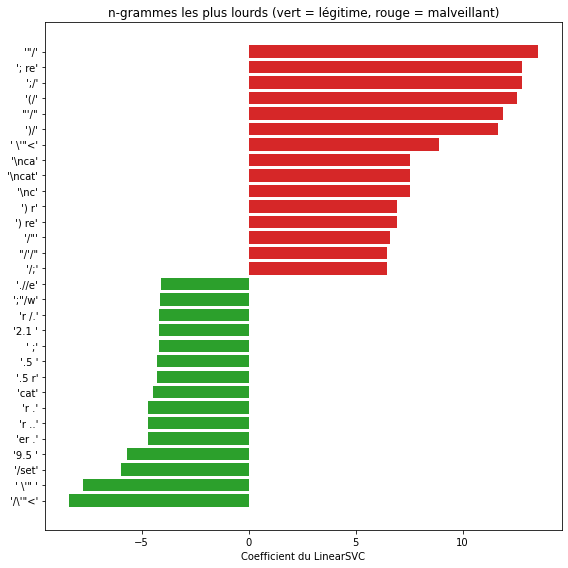

In [ ]:
interp = gs.best_estimator_
noms = interp.named_steps["tfidf"].get_feature_names_out()
coefs = pd.Series(interp.named_steps["clf"].coef_[0], index=noms).sort_values()
sel = pd.concat([coefs.head(15), coefs.tail(15)])

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh([repr(n) for n in sel.index], sel.values, color=["tab:green"] * 15 + ["tab:red"] * 15)
ax.set_title("n-grammes les plus lourds (vert = légitime, rouge = malveillant)")
ax.set_xlabel("Coefficient du LinearSVC")
plt.tight_layout()
plt.savefig("../rapport/fig_coefficients.png", bbox_inches="tight", dpi=150)
plt.show()

## 8. Export

Le modèle exporté est le pipeline complet (TF-IDF + LinearSVC calibré) : l'API appelle predict_proba sur le texte et bloque si la probabilité dépasse le seuil de seuil.txt.

> Pour l'API : le texte doit être construit exactement comme dans la partie 1 (build_text_df : Host/Referer normalisés, URL décodée deux fois, minuscules).

In [ ]:
joblib.dump(final, "../models/waf.joblib")
with open("../models/seuil.txt", "w") as f:
    f.write(str(SEUIL))

# Test de rechargement : mêmes probabilités avant / après
m = joblib.load("../models/waf.joblib")
check = X_test.iloc[:500]
assert np.allclose(m.predict_proba(check)[:, 1], final.predict_proba(check)[:, 1])
print("Rechargement OK, seuil =", SEUIL)

for lab in (0, 1):
    for t in X_test[y_test == lab].sample(2, random_state=42):
        print(f"label={lab}  proba={m.predict_proba([t])[0, 1]:.3f}  {t[:90]}")

Rechargement OK, seuil = 0.24576028783698792
label=0  proba=0.985  request_http_method post request_http_request /blog//../../../../../../../../../../../../.
label=0  proba=0.005  request_http_method get request_http_request /blog/index.php||cat+/etc/passwd/et-vel-qui-e
label=1  proba=0.999  request_http_method get request_http_request /blog&&sleep+15/wp-content/plugins/user-regis
label=1  proba=1.000  request_http_method get request_http_request /blog/index.php/2020/03/27/qui-ratione-maxime


# Partie 3 : Modèle à marqueurs

Des marqueurs experts (longueurs, signatures SQL / XSS / traversal, contexte de la requête) calculés par marqueurs() de preprocessing.py, évalués seuls puis combinés au TF-IDF.

In [ ]:
# Cette partie travaille sur l'échantillon de 50 000 requêtes (puis train.parquet pour confirmer)
train = pd.read_parquet("../data/sample.parquet")
X_train, y_train = train["text"], train["label"]

## Étape 1 : les marqueurs candidats

La fonction `marqueurs()` calcule **24 marqueurs candidats** (`marqueurs(X, tous=True)`) :
- Forme : longueur_url, longueur_body, nb_parametres, nb_guillemets, nb_speciaux, ratio_speciaux, entropie_url.
- Signatures : nb_mots_sql (nombre de mots-clés SQL distincts), contient_union_select, contient_sql_tautologie, contient_commentaire_sql, contient_traversal, contient_fichier_sensible, contient_xss, contient_cmd, contient_crlf, contient_null_byte.
- Contexte : methode_inhabituelle, protocole_inhabituel, host_etranger, user_agent_vide, user_agent_outil (sqlmap, nikto, curl…), cible_wordpress, referer_externe.

Par défaut (`marqueurs(X)`), elle ne renvoie que les 14 marqueurs retenus après la sélection de l'étape 2 bis (`MARQUEURS_RETENUS`). Les étapes 1 et 2 analysent les 24 candidats.

In [ ]:
M = marqueurs(X_train, tous=True)      # les 24 candidats, pour l'analyse
M.head()

## Étape 2 : analyse des marqueurs candidats

In [ ]:
analyse = M.groupby(y_train.values).mean().T
analyse.columns = ["moyenne légitimes", "moyenne malveillantes"]
analyse["écart"] = (analyse["moyenne malveillantes"] - analyse["moyenne légitimes"]).abs()
analyse.sort_values("écart", ascending=False).round(3)

### Écart standardisé

L'écart brut dépend de l'échelle du marqueur (`longueur_url` se compte en dizaines, un marqueur binaire ne dépasse pas 1) : on le divise par l'écart-type du marqueur pour pouvoir comparer les marqueurs entre eux (taille d'effet, proche du *d* de Cohen). On garde aussi le **sens** : un écart négatif signifie que le marqueur est plus fréquent chez les requêtes légitimes.

In [ ]:
std = M.std().replace(0, np.nan)          # écart-type nul -> marqueur constant
analyse["écart standardisé"] = (analyse["moyenne malveillantes"] - analyse["moyenne légitimes"]) / std
analyse["sens"] = np.where(analyse["écart standardisé"] >= 0, "↑ malveillantes", "↑ légitimes")
analyse.sort_values("écart standardisé", key=abs, ascending=False).round(3)

### AUC de chaque marqueur pris seul

On utilise la valeur du marqueur directement comme score de prédiction. AUC = 0,5 : le marqueur ne sépare rien. AUC proche de 1 : il sépare bien. AUC < 0,5 : il est **inversé** (plus élevé chez les légitimes).

In [ ]:
from sklearn.metrics import roc_auc_score

analyse["AUC seule"] = [roc_auc_score(y_train, M[c]) if M[c].nunique() > 1 else 0.5
                        for c in analyse.index]
analyse.sort_values("AUC seule", ascending=False).round(3)

In [ ]:
auc = analyse["AUC seule"].sort_values()
couleurs = ["tab:red" if v < 0.5 else "tab:green" for v in auc]
ax = (auc - 0.5).plot.barh(color=couleurs, left=0.5, figsize=(7, 7),
                           title="AUC de chaque marqueur seul (rouge = inversé)")
ax.axvline(0.5, color="black", lw=1)
ax.set_xlabel("AUC")
plt.savefig("../rapport/fig_auc_marqueurs.png", bbox_inches="tight")
plt.show()

### Distribution des marqueurs continus

Une moyenne ne montre pas la dispersion : on regarde la distribution par classe des marqueurs non binaires.

In [ ]:
continus = ["longueur_url", "longueur_body", "nb_mots_sql", "nb_guillemets", "nb_speciaux", "entropie_url"]
classe = y_train.map({0: "légitime", 1: "malveillante"}).values

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), continus):
    M.boxplot(column=col, by=classe, ax=ax, showfliers=False)
    ax.set_title(col); ax.set_xlabel("")
fig.suptitle("Marqueurs continus par classe (sans valeurs extrêmes)")
plt.tight_layout()
plt.savefig("../rapport/fig_boxplots_marqueurs.png", bbox_inches="tight")
plt.show()

### Marqueurs inversés : vérification sur des exemples

`contient_fichier_sensible`, `contient_cmd`, `contient_xss` et `contient_null_byte` sont plus fréquents chez les légitimes. On affiche des requêtes **étiquetées légitimes** qui les déclenchent, pour vérifier si c'est le marqueur ou le label qui pose problème.

In [ ]:
inverses = ["contient_fichier_sensible", "contient_cmd", "contient_xss", "contient_null_byte"]
for col in inverses:
    legit = X_train[(M[col] == 1) & (y_train == 0)]
    print(f"--- {col} : {len(legit)} requêtes légitimes concernées")
    for t in legit.head(2):
        url = t.split(" request_http_protocol ")[0].replace("request_http_method ", "")
        print("   ", url[:160])

### Interprétation

**Lecture du tableau.** Pour un marqueur binaire (`contient_*`, `user_agent_*`…), la moyenne est la proportion de requêtes concernées : `contient_union_select` = 0,227 signifie que 22,7 % des requêtes malveillantes en contiennent un. L'écart brut n'est pas comparable d'un marqueur à l'autre (il dépend de l'échelle) : on s'appuie sur l'écart standardisé et l'AUC.

**1. Signatures précises mais partielles.** `contient_union_select` (0 % / 22,7 %), `contient_sql_tautologie` (0 % / 12,7 %), `contient_crlf` (0 % / 5,7 %), `contient_traversal` (0,1 % / 4,2 %) : quand ils valent 1, la requête est presque toujours malveillante (précision élevée), mais chacun ne couvre qu'une petite part des attaques (rappel faible). C'est le comportement normal d'une signature, d'où l'intérêt de les combiner.

**2. Les meilleurs marqueurs seuls** sont liés au SQL et à la forme de la requête : `nb_mots_sql` (AUC 0,69, moyenne ×15), `longueur_url` (0,67), `contient_commentaire_sql` (0,64), `nb_guillemets` (0,63). C'est cohérent avec la dominance de SQL Injection dans le dataset. Aucun marqueur ne dépasse 0,7 seul : c'est leur **combinaison** qui fait la performance (F1 ≈ 0,94 avec une Random Forest sur les seuls marqueurs).

**3. Marqueurs inversés (AUC < 0,5) : bruit de labels.** `contient_fichier_sensible` (AUC 0,44), `contient_cmd` (0,46), `contient_xss` et `contient_null_byte` sont plus fréquents chez les requêtes *légitimes*. Les exemples ci-dessus montrent que ce ne sont pas des erreurs du marqueur : des requêtes contenant `` `cat /etc/passwd` `` ou `<script>alert(1);</script>` sont étiquetées `000 - Normal` dans SR-BH. Conséquence : le modèle risque d'apprendre que `/etc/passwd` est un signe de légitimité, ce qui serait dangereux en production. On signale cette limite du dataset dans le rapport ; le sort de ces marqueurs est décidé à l'étape 2 bis.

**4. Marqueurs sans pouvoir séparateur seuls** (AUC ≈ 0,5) : `protocole_inhabituel` (constant, à retirer), `nb_parametres`, `methode_inhabituelle`, `entropie_url`, `cible_wordpress`, `referer_externe`, `host_etranger`, `user_agent_outil`, `user_agent_vide`. Les plus rares (< 1 % des requêtes) ne pèsent pas sur ce dataset mais restent utiles face à de vrais outils (sqlmap, nikto). Avant d'en supprimer, on vérifie à l'étape 2 bis qu'ils n'apportent rien **en combinaison** : un arbre peut exploiter un marqueur inutile seul.

**Limites.** Analyse univariée (pas d'interactions) et calculée sur sample.parquet (50 000 requêtes) : à relancer sur train.parquet.

## Étape 2 bis : sélection des marqueurs

But : ne garder dans `marqueurs()` que les marqueurs **utiles**, pour un modèle plus simple, plus lisible et plus rapide en production. La démarche se fait en trois temps :

1. **Premier filtre par l'AUC** (graphique ci-dessus) : on écarte les marqueurs qui ne séparent rien seuls, ou qui séparent « à l'envers ».
2. **Vérification en combinaison** par ablation : un marqueur inutile seul peut servir combiné aux autres (« long ET avec beaucoup de paramètres »), ce que l'AUC ne voit pas. On retire chaque marqueur un par un et on mesure la perte.
3. **Décision, puis validation** : on compare les modèles avec les 24 candidats et avec les marqueurs retenus (ici sur les marqueurs seuls, et à l'étape 5 sur le mix TF-IDF + marqueurs, qui est le modèle à déployer).

On commence par définir les outils d'évaluation communs (mêmes folds et mêmes métriques que le notebook TF-IDF). Les 5 folds sont calculés **en parallèle** (`n_jobs=5`) : la latence mesurée est donc légèrement pessimiste.

In [ ]:
# cv et fpr : définis dans la partie 2 (mêmes plis, même métrique)
scoring = {"f1": "f1", "precision": "precision", "recall": "recall", "fpr": make_scorer(fpr)}

def evaluer(nom, modele, X, y):
    s = cross_validate(modele, X, y, cv=cv, scoring=scoring, n_jobs=cv.get_n_splits())
    n_test = len(y) / cv.get_n_splits()
    return {"modèle": nom,
            "F1": f"{s['test_f1'].mean():.4f} ± {s['test_f1'].std():.4f}",
            "précision": round(s["test_precision"].mean(), 4),
            "rappel": round(s["test_recall"].mean(), 4),
            "FPR": round(s["test_fpr"].mean(), 4),
            "prédiction (s / fold)": round(s["score_time"].mean(), 2),
            "latence (ms / requête)": round(s["score_time"].mean() / n_test * 1000, 4)}

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
models = {
    "LogReg": Pipeline([("scaler", StandardScaler()),
                        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                           n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                             scale_pos_weight=neg / pos, n_jobs=-1, eval_metric="logloss"),
}

### 1. Premier filtre : l'AUC de chaque marqueur seul

Seuil : **AUC ≥ 0,51**. En dessous, le marqueur est soit neutre (AUC ≈ 0,5), soit inversé (AUC < 0,5).

In [ ]:
SEUIL_AUC = 0.51
filtre_auc = analyse.index[analyse["AUC seule"] >= SEUIL_AUC].tolist()
ecartes = analyse.loc[analyse["AUC seule"] < SEUIL_AUC, ["AUC seule"]].copy()
ecartes["raison"] = np.where(ecartes["AUC seule"] < 0.49, "inversé (bruit de labels)", "neutre")

print(f"{len(filtre_auc)} marqueurs passent le filtre AUC :", filtre_auc)
ecartes.sort_values("AUC seule").round(3)

### 2. Vérification en combinaison : ablation

Pour chaque marqueur, on entraîne un XGBoost sur les 23 autres et on mesure ce qu'on perd par rapport au modèle complet. Une perte de F1 positive signifie que le marqueur apporte quelque chose **en combinaison** ; une perte nulle ou négative, qu'on peut le retirer sans dommage.

In [ ]:
def scores(modele, X, y):
    s = cross_validate(modele, X, y, cv=cv, scoring={"f1": "f1", "fpr": make_scorer(fpr)},
                       n_jobs=cv.get_n_splits())
    return s["test_f1"].mean(), s["test_fpr"].mean()

xgb = models["XGBoost"]
f1_ref, fpr_ref = scores(xgb, M, y_train)

ablation = []
for col in M.columns:
    f1_sans, fpr_sans = scores(xgb, M.drop(columns=col), y_train)
    ablation.append({"marqueur": col, "AUC seule": analyse.loc[col, "AUC seule"],
                     "perte F1 si retiré": f1_ref - f1_sans,
                     "hausse FPR si retiré": fpr_sans - fpr_ref})

ablation = pd.DataFrame(ablation).set_index("marqueur").sort_values("perte F1 si retiré", ascending=False)
print(f"Référence (24 marqueurs, XGBoost) : F1 {f1_ref:.4f}, FPR {fpr_ref:.4f}")
ablation.round(4)

### 3. Décision et validation

On garde les **12 marqueurs qui passent le filtre AUC**, plus **2 marqueurs repêchés par l'ablation** : `nb_parametres` et `methode_inhabituelle` sont neutres seuls, mais les retirer fait perdre du F1 et augmente le FPR. Ce sont les 14 marqueurs de `MARQUEURS_RETENUS` dans preprocessing.py.

On écarte les 10 autres :

| Marqueur | Raison |
|---|---|
| `protocole_inhabituel` | constant sur le dataset |
| `host_etranger`, `user_agent_vide`, `cible_wordpress`, `contient_null_byte`, `contient_xss` | neutres seuls et sans apport en combinaison |
| `user_agent_outil` | sans apport ; le TF-IDF voit de toute façon `sqlmap` ou `nikto` dans le texte du User-Agent |
| `referer_externe` | sans apport, et cohérent avec le retrait du Referer (étape 7) |
| `contient_cmd`, `contient_fichier_sensible` | **inversés** : leur signal vient du bruit de labels (`` `cat /etc/passwd` `` étiqueté légitime). Les garder apprendrait au modèle qu'une injection de commande est un signe de légitimité : on les retire **volontairement**, même si cela coûte un peu de F1 sur ce dataset. |

In [ ]:
attendus = filtre_auc + ["nb_parametres", "methode_inhabituelle"]
assert set(attendus) == set(MARQUEURS_RETENUS), "MARQUEURS_RETENUS ne correspond pas à la démarche"

comparaison = []
for n, m in models.items():
    for nom, cols in [("24 candidats", M.columns), ("14 retenus", MARQUEURS_RETENUS)]:
        f1_, fpr_ = scores(m, M[cols], y_train)
        comparaison.append({"modèle": n, "marqueurs": nom, "F1": f1_, "FPR": fpr_})
pd.DataFrame(comparaison).pivot(index="modèle", columns="marqueurs").round(4)

**Interprétation (sur sample.parquet).**
- **Le filtre AUC seul ne suffit pas.** Avec seulement les 12 marqueurs qui le passent, XGBoost perd 2,3 points de F1 (0,925 → 0,902) et la Random Forest 2,1 points. L'ablation explique pourquoi : `nb_parametres` (AUC 0,500) est le 4e marqueur le plus utile en combinaison (−0,009 de F1 si on le retire), et `methode_inhabituelle` (AUC 0,499) coûte aussi 0,004. D'où leur repêchage.
- **Les 10 marqueurs écartés n'apportent presque rien en combinaison** (perte ≤ 0,0003 de F1), sauf `contient_fichier_sensible` (−0,005) : son apport vient du bruit de labels, c'est justement ce qu'on ne veut pas apprendre.
- **Inversement, deux marqueurs retenus par l'AUC sont redondants** : `contient_union_select` et `contient_traversal` ne coûtent rien si on les retire (leur information est déjà dans `nb_mots_sql` et les comptages). On les garde car ils sont lisibles et pertinents sur du trafic réel.
- **Coût de la sélection sur les marqueurs seuls** : environ −1 point de F1 (Random Forest 0,940 → 0,930, XGBoost 0,925 → 0,915). C'est en partie le prix du retrait des marqueurs inversés : le modèle à 24 marqueurs « gagnait » en exploitant des erreurs d'étiquetage.
- **Sur le modèle à déployer (mix TF-IDF + marqueurs, étape 5), la sélection ne coûte rien** : F1 0,9682 → 0,9672 (écart inférieur à l'écart-type entre folds) et le **FPR baisse** (1,68 % → 1,54 %). Le TF-IDF couvre ce que les marqueurs retirés apportaient.

**Conclusion** : `marqueurs()` renvoie désormais 14 marqueurs au lieu de 24, pour un modèle plus simple, plus lisible, et qui ne s'appuie plus sur le bruit de labels du dataset.

# Modèles

## Étape 3 : précalcul des marqueurs

`marqueurs()` n'apprend rien des données (pas de `fit`) : on peut la calculer **une seule fois** avant la cross-validation, sans risque de fuite. C'est beaucoup plus rapide que de la recalculer dans chaque fold. Ils ont déjà été calculés à l'étape 1 (`M`) : on garde seulement les colonnes retenues, et on mesure le coût de `marqueurs()` par requête sur un échantillon, car il s'ajoute à la latence du modèle en production.

In [ ]:
M_train = M[MARQUEURS_RETENUS]      # déjà calculé à l'étape 1, inutile de le refaire

echantillon = X_train.iloc[:5000]
t0 = time.perf_counter()
marqueurs(echantillon)
duree = time.perf_counter() - t0
print(f"{M_train.shape[1]} marqueurs, {duree / len(echantillon) * 1000:.3f} ms / requête")

## Étape 4 : modèles sur les marqueurs retenus

Les outils d'évaluation (`cv`, `scoring`, `evaluer`) et les modèles sont définis à l'étape 2 bis.

In [ ]:
res = pd.DataFrame([evaluer(f"Marqueurs + {n}", m, M_train, y_train) for n, m in models.items()])
res.set_index("modèle")

**Interprétation (sur sample.parquet, 14 marqueurs retenus).**
- Le `StandardScaler` de la LogReg met les marqueurs à la même échelle (sinon `longueur_url` ≈ 70 écrase `contient_union_select` ∈ {0, 1}) ; il est inutile pour les arbres, qui ne comparent qu'un marqueur à un seuil.
- La **LogReg** est nettement en dessous (F1 0,82, rappel 0,73) : un modèle linéaire ne peut pas combiner les marqueurs (« long ET avec guillemets »).
- La **Random Forest** a le meilleur F1 (0,93) grâce à son rappel (0,91), mais un FPR élevé (10 %).
- **XGBoost** a un F1 un peu plus bas (0,915) mais un FPR deux fois plus faible (5,3 %) et la meilleure précision (0,972). Pour un WAF, où bloquer un vrai utilisateur coûte cher, c'est le meilleur compromis des modèles « marqueurs seuls ».
- Les latences sont négligeables (< 0,05 ms / requête), auxquelles s'ajoute le calcul des marqueurs (≈ 0,04 ms / requête).

## Étape 5 : mix TF-IDF + marqueurs

`FeatureUnion` met côte à côte les colonnes TF-IDF (n-grammes de caractères) et les colonnes marqueurs (standardisées) : le modèle profite des deux. On passe ici le **texte** (`X_train`) et non `M_train` : le pipeline calcule lui-même les deux types de features. C'est cette forme qu'il faudra exporter si le mix gagne, car l'API ne reçoit que du texte.

On évalue aussi le même mix avec les 24 marqueurs candidats, pour vérifier que la sélection de l'étape 2 bis ne dégrade pas le modèle à déployer.

Paramètres TF-IDF et classifieur provisoires (LogReg) : ce n'est pas le LinearSVC réglé de la partie 2.

In [ ]:
# float32 : deux fois moins de mémoire que float64 (important sur train.parquet), sans perte mesurable
TFIDF_PARAMS = dict(analyzer="char", ngram_range=(1, 3), max_features=50_000, sublinear_tf=True,
                    dtype=np.float32)

mix = Pipeline([
    ("features", FeatureUnion([
        ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
        ("marq", Pipeline([("f", FunctionTransformer(marqueurs)),
                           ("s", StandardScaler())])),
    ])),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])

res_mix = evaluer("Mix TF-IDF + marqueurs (LogReg)", mix, X_train, y_train)

# Validation de la sélection sur le modèle à déployer : même mix avec les 24 candidats
mix_24 = clone(mix).set_params(features__marq__f__kw_args={"tous": True})
res_mix_24 = evaluer("Mix TF-IDF + 24 marqueurs (LogReg)", mix_24, X_train, y_train)

pd.DataFrame([res_mix, res_mix_24]).set_index("modèle")

## Étape 6 : tableau comparatif

Mêmes données, mêmes folds, mêmes métriques. La ligne « TF-IDF seul » sert de référence (LogReg, paramètres provisoires) ; elle est aussi réutilisée à l'étape 7 comme modèle « avec Referer ».

In [ ]:
best_tfidf = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])     # LogReg provisoire (pas le LinearSVC réglé de la partie 2)

res_tfidf = evaluer("TF-IDF seul (LogReg)", best_tfidf, X_train, y_train)

comparatif = pd.DataFrame(res.to_dict("records") + [res_tfidf, res_mix, res_mix_24]).set_index("modèle")
comparatif

**Interprétation.**
- Les marqueurs seuls restent en dessous du TF-IDF (F1 0,93 contre 0,964, FPR 5 à 10 % contre 3 %) : une quinzaine de questions fixées à la main ne capturent pas toute la variété des payloads, que les n-grammes de caractères voient directement.
- Le **mix** est le meilleur : F1 0,967, précision 0,992 et surtout un **FPR divisé par deux** par rapport au TF-IDF seul (1,5 % contre 3,0 %). Les marqueurs apportent une information de structure (comptages, signatures) que le TF-IDF ne résume pas bien.
- Le mix avec les 24 candidats a un F1 quasi identique (0,968, écart inférieur à l'écart-type) mais un FPR plus élevé (1,7 %) : la sélection de l'étape 2 bis est validée sur le modèle à déployer.
- Latence : environ 0,5 ms par requête pour les pipelines TF-IDF (mesure pessimiste, les folds tournent en parallèle) ; c'est acceptable pour un WAF.
- Ces comparaisons utilisent une LogReg sur l'échantillon : à confirmer sur train.parquet et avec le LinearSVC réglé de la partie 2.

## Étape 7 : expérience avec / sans Referer

Le Referer est très corrélé à la classe dans le dataset, mais c'est probablement un artefact : un vrai navigateur envoie un Referer à presque chaque requête. On vide le champ dans le texte (le format est `request_referer <valeur> request_host ...`) et on compare.

In [ ]:
X_sans_ref = X_train.str.replace(r"request_referer .*? request_host ", "request_referer  request_host ", regex=True)

i = X_train.str.contains(r"request_referer \S").idxmax()      # une requête qui a un Referer
print("Avant :", X_train[i][X_train[i].find("request_referer"):][:120])
print("Après :", X_sans_ref[i][X_sans_ref[i].find("request_referer"):][:120])
print("Requêtes encore avec un Referer :", X_sans_ref.str.contains(r"request_referer \S").sum())

In [ ]:
res_sans_ref = evaluer("Sans Referer", best_tfidf, X_sans_ref, y_train)

referer = pd.DataFrame([{**res_tfidf, "modèle": "Avec Referer"}, res_sans_ref]).set_index("modèle")
referer

**Interprétation.** Sans Referer, le score ne baisse pas : le F1 est identique (0,9635 → 0,9636) et le **FPR baisse** (3,0 % → 2,6 %). Le Referer n'apporte donc pas d'information utile au modèle : sa corrélation avec la classe est un biais du dataset, et le modèle en tirait même des faux positifs. **Conclusion : on retire le Referer du modèle déployé** (moins de risque de faux positifs en démo, où un vrai navigateur envoie un Referer à chaque requête).

## Étape 8 : importance des marqueurs

Importance (réduction moyenne d'impureté) d'une Random Forest entraînée sur tous les marqueurs du train.

In [ ]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(M_train, y_train)

imp = pd.Series(rf.feature_importances_, index=M_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
imp.plot.barh(ax=ax, title="Importance des marqueurs (Random Forest)")
plt.savefig("../rapport/fig_importance_marqueurs.png", bbox_inches="tight")
plt.show()

**Interprétation (14 marqueurs retenus).**
- Les marqueurs les plus utilisés par la forêt sont les marqueurs **continus de forme** (`entropie_url`, `ratio_speciaux`, `longueur_url`, `nb_speciaux`) et **SQL** (`nb_mots_sql`, `contient_commentaire_sql`, `nb_guillemets`). C'est cohérent avec la dominance des injections SQL dans le dataset.
- `entropie_url` arrive en tête alors que son AUC seule n'est que de 0,51 (étape 2). Deux raisons : l'importance par impureté **favorise les variables continues** (beaucoup de seuils possibles), et l'entropie n'est utile qu'en **combinaison** avec d'autres marqueurs. L'ablation de l'étape 2 bis, plus fiable, la place plutôt au milieu du classement (−0,004 de F1 si on la retire).
- `methode_inhabituelle` a une importance faible (0,006) mais l'ablation montre qu'elle réduit le F1 quand on la retire : un marqueur rare peut être peu utilisé et pourtant décisif sur les requêtes où il s'active.
- Aucun marqueur lié au Host ou au Referer ne reste : le modèle ne peut plus s'appuyer sur ces biais du dataset.

# Partie 4 : Tests du modèle

> **Section à compléter.** Le fichier 04_tests.ipynb de l'archive est vide : coller ici les cellules de tests (requêtes d'attaque, mesure des faux positifs sur une navigation réelle, tests sur la stack Docker).

# Partie 5 : Synthèse

**Modèle exporté** (models/waf.joblib) : TF-IDF sur n-grammes de caractères, puis LinearSVC calibré (CalibratedClassifierCV) pour disposer de predict_proba. Le seuil est choisi sur une validation interne au train pour bloquer au plus 1 % des requêtes légitimes, puis fixé avant l'évaluation sur le test. Le seuil est écrit dans models/seuil.txt.

**Résultats finaux sur le test** (jamais utilisé avant ce point) :

In [ ]:
synthese = pd.Series({
    "F1": f1_score(y_test, y_pred),
    "précision": precision_score(y_test, y_pred),
    "rappel": recall_score(y_test, y_pred),
    "FPR": fpr(y_test, y_pred),
    "seuil": SEUIL,
    "latence (ms / requête)": lat,
}).round(4)
synthese

**Ce que montrent les expériences**

- Le F1 seul ne suffit pas (la baseline « toujours malveillant » atteint déjà 0,811) : le taux de faux positifs (FPR) mesure les vrais clients bloqués et sert de critère principal.
- Les n-grammes de caractères battent les mots ; le LinearSVC est presque aussi bon que XGBoost pour environ quatre fois moins de temps de calcul.
- Les marqueurs seuls restent en dessous du TF-IDF, mais combinés à un TF-IDF avec LogReg ils divisent le FPR par deux (partie 3). Les marqueurs inversés (`contient_cmd`, `contient_fichier_sensible`…) viennent de bruit de labels du dataset et sont volontairement écartés.
- Le code HTTP de réponse est écarté : il fuit le label (règle « 200 = légitime » à environ 82 % d'accuracy) et n'existe pas au moment où un WAF décide.

**Limites et pistes**

- Un seul site (WordPress), données de 2020, labels en partie issus de ModSecurity, avec du bruit de labels (par exemple des requêtes `cat /etc/passwd` étiquetées légitimes).
- Le mix TF-IDF + marqueurs n'a été évalué qu'avec une LogReg sur l'échantillon : l'associer au LinearSVC réglé est une piste non explorée.
- L'expérience sans Referer (partie 3) donne un FPR plus bas à F1 égal avec la LogReg ; le modèle exporté garde le Referer (normalisé), cette piste reste à tester sur le LinearSVC.
- Le texte envoyé à l'API doit être construit exactement comme dans la partie 1 (build_text_df de preprocessing.py).